In [46]:
from plot_utils import *
from feature_extraction import *
from ml_networks import *

import pathlib
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, clear_output

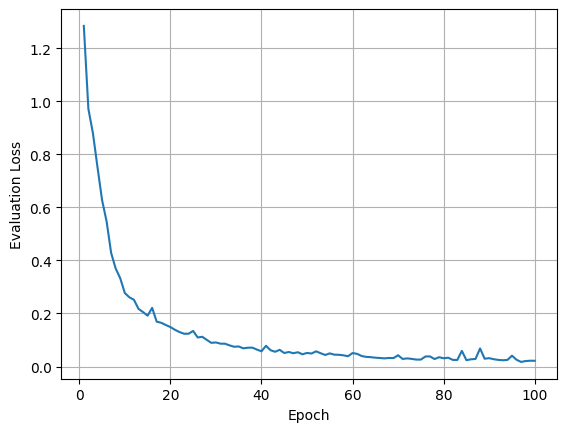

In [49]:
MODEL = "sunli"

for ALGO in ["nobec", "cropac", "mvdr"]:
    for FEAT in ["stft", "mfcc"]:
        for TRAINING_DATA in ["real", "synthetic", "mixture"]:
            
            training_types = {
                "real": ["../dataset/real_training"],
                "synthetic": ["../dataset/synthetic_training"],
                "mixture": ["../dataset/real_training", "../dataset/synthetic_training"]
            }

            training_paths = training_types[TRAINING_DATA]

            label_conversion = {
                "noise": 0,
                "neo": 1,
                "mini3": 2,
                "mavic4": 3
            }

            num_classes = 4

            label_invert = {}
            for k, v in label_conversion.items():
                label_invert[v] = k

            def build_training_dataset(paths, algorithm, feature, size):
                data = {}
                data_size = {}

                for k in label_conversion.keys():
                    data[k] = []
                    data_size[k] = 0
                for path in paths:
                    path_files = [p.relative_to(".") for p in pathlib.Path(path).rglob("*.npy")]
                    for pf in path_files:
                        label, number, algo, feat = str(pf.with_suffix("").name).split("_")
                        if algo == algorithm and feat == feature:
                            with open(str(pf), "rb") as fil:
                                d = np.load(fil)
                                data[label].append(d)
                                data_size[label] += d.shape[0] - FEATURE_LENGTH*4

                inputs = []
                labels = []
                for label, raw_data in data.items():
                    step = data_size[label] // (size // 4)
                    for d in raw_data:
                        for i in range(3*FEATURE_LENGTH, len(d)-FEATURE_LENGTH, step):
                            if feature == "mfcc":
                                inputs.append(normalize_raw_mfcc(d[i:i+FEATURE_LENGTH]))
                            else:
                                inputs.append(normalize_raw_stft(d[i:i+FEATURE_LENGTH]))
                            labels.append(label_conversion[label])

                return np.array(inputs), np.array(labels)

            width = NMFCC if FEAT == "mfcc" else NSTFT
            height = FEATURE_LENGTH
            channels = 1
            features, labels = build_training_dataset(training_paths, ALGO, FEAT, 5000)
            eval_idx = np.random.choice(len(features), 500, replace=False)
            train_idx = np.ones(len(features), dtype=np.bool)
            train_idx[eval_idx] = False
            train_features, train_labels = features[train_idx], labels[train_idx]
            eval_features, eval_labels = features[eval_idx], labels[eval_idx]

            def prepare_features(images):
                images = np.asarray(images, dtype=np.float32)

                # Reshape flattened images to PyTorch's NCHW format.
                images = images.reshape(-1, channels, height, width)

                return torch.from_numpy(images)

            def prepare_labels(labels, num_classes):
                labels = np.asarray(labels)

                # Convert one-hot labels (N, Q) to class indices if needed.
                if labels.ndim == 2:
                    labels = labels.argmax(axis=1)

                return torch.as_tensor(labels, dtype=torch.long)

            X_train = prepare_features(train_features)
            y_train = prepare_labels(train_labels, num_classes)
            X_eval = prepare_features(eval_features)
            y_eval = prepare_labels(eval_labels, num_classes)

            train_loader = DataLoader(
                TensorDataset(X_train, y_train),
                batch_size=128,
                shuffle=True,
            )

            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

            model = SunLiCNN(width, height, num_classes).to(device)
            loss_fn = nn.CrossEntropyLoss()
            optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

            # Evaluate the held-out data after each training epoch.
            epochs = 100
            eval_losses = []

            fig, ax = plt.subplots()

            for epoch in range(epochs):
                model.train()
                for images, labels in train_loader:
                    images, labels = images.to(device), labels.to(device)

                    optimizer.zero_grad()
                    logits = model(images)
                    loss = loss_fn(logits, labels)
                    loss.backward()
                    optimizer.step()

                model.eval()
                with torch.no_grad():
                    logits = model(X_eval.to(device))
                    eval_loss = loss_fn(logits, y_eval.to(device)).item()

                eval_losses.append(eval_loss)

                ax.clear()
                ax.plot(range(1, epoch + 2), eval_losses)
                ax.set_xlabel("Epoch")
                ax.set_ylabel("Evaluation Loss")
                ax.grid(True)

                clear_output(wait=True)
                display(fig)

            plt.close(fig)

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "height": height,
                    "width": width,
                    "channels": channels,
                    "num_classes": num_classes,
                },
                f"../weights/{ALGO}_{FEAT}_{TRAINING_DATA}_{MODEL}.pth",
            )

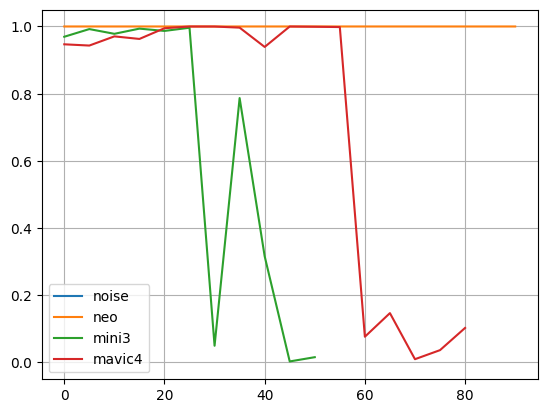

In [50]:
def process_measurement(path, algorithm, feature):
    data = {}
    inputs = {}
    distances = {}

    for k in label_conversion.keys():
        data[k] = []
        inputs[k] = []
        distances[k] = []

    path_files = [p.relative_to(".") for p in pathlib.Path(path).rglob("*.npy")]
    for pf in path_files:
        label, distance, algo, feat = str(pf.with_suffix("").name).split("_")
        if algo == algorithm and feat == feature:
            with open(str(pf), "rb") as fil:
                d = np.load(fil)
                data[label].append((d, int(distance)))

    for label, raw_data in data.items():
        for (d, dist) in raw_data:
            if feature == "mfcc":
                inputs[label].append(normalize_raw_mfcc(d[-FEATURE_LENGTH:]))
            else:
                inputs[label].append(normalize_raw_stft(d[-FEATURE_LENGTH:]))
            distances[label].append(dist)

    for k in label_conversion.keys():
            inputs[k] = np.array(inputs[k])
            distances[k] = np.array(distances[k])
            order = [i for i in range(len(distances[k]))]
            order = sorted(order, key=lambda idx: distances[k][idx])
            distances[k] = distances[k][order]
            inputs[k] = inputs[k][order]
    
    return inputs, distances

inputs, distances = process_measurement("../dataset/real_meas1", ALGO, FEAT)

fig, ax = plt.subplots()

model.eval()
for label in inputs.keys():
    results = []
    for i in range(len(inputs[label])):
        x = prepare_features(inputs[label][i][None, ...]).to(device)
        with torch.no_grad():
            output = nn.functional.softmax(model(x), dim=1)
        output = output.squeeze(0).cpu().numpy()
        results.append(output[label_conversion[label]])
    ax.plot(distances[label], results, label=label)

ax.set_ylim([-0.05, 1.05])
ax.grid()
ax.legend()
